## Import Statements

In [45]:
import os
from pathlib import Path 

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_curve, roc_auc_score, accuracy_score, f1_score, confusion_matrix, precision_score
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from collections import Counter
import joblib


## Export Paths

In [46]:
# Get the project root directory (one level up from the 'notebooks' folder)
ROOT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()

# Define absolute paths for output directories
REPORTS_DIR = ROOT_DIR / 'reports'
FIGURES_DIR = REPORTS_DIR / 'figures'
TABLES_DIR = REPORTS_DIR / 'tables'
MODELS_DIR = ROOT_DIR / 'models'

# Ensure directories exist at the root level
os.makedirs(FIGURES_DIR, exist_ok=True)
os.makedirs(TABLES_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

## Load Data

In [47]:
df = pd.read_csv(f'{ROOT_DIR}/data/mock_data/mock_data.csv') # MOCK DATA

## Data Cleanup


VERY IMPORTANT: Make sure you do REMOVE any "leaky features". That is, variables that would leak the outcome you're trying to predict. This can include:
- DMFT
- Number of new cavities this year → directly tells the model the outcome

ALSO MAKE SURE TO DELETE PATIENT IDENTIFIERS:
- patient_code

In [48]:
target_col = 'caries_risk'
leaky_cols = ['dmft_d', 'dmft_m', 'dmft_f', 'dmft_total']
ignore_cols = ['patient_code', target_col] + leaky_cols

In [49]:
# Separate features (X) and target (y)
X = df.drop(columns=ignore_cols)
y = df[target_col]

## Data Exploration

In [50]:
# Check outputs
print(X.head())
print(y.value_counts())

    age  sex  ...  restorations_present  active_carious_lesions_count
0  56.0  1.0  ...                   5.0                           7.0
1  46.0  1.0  ...                   1.0                           1.0
2  32.0  NaN  ...                   0.0                           NaN
3  60.0  0.0  ...                   0.0                           7.0
4   NaN  1.0  ...                   8.0                           3.0

[5 rows x 26 columns]
caries_risk
1    180
0    120
Name: count, dtype: int64


## Train Test Split

We will do a 70-30 split.

**IMPORTANT: DO NOT RUN TRAIN-TEST-SPLIT MORE THAN ONCE** to avoid data leakage!!

In [51]:
X_train, X_test, y_train, y_test = train_test_split(X, 
                                                    y, 
                                                    test_size=0.3, 
                                                    random_state=42)

## Setup Pipelines

Instantiate the pipelines for the three models. For caries risk prediction, we will be using **classification models** as we will be predicting categorical labels (low/high caries risk)

**1. Logistic Regression**

We use a logistic regression model as a baseline for our other models: Random Forest and XGBoost. Logistic regression models are used to predict binary probabilities (low/high caries risk) by modeling the log-odds of the outcome as a linear combination of input features.

**2. Random Forest**

Random Forest is an ensemble learning method that constructs a collection of independent decision trees during training. By combining the predictions of multiple trees (via majority voting), it reduces model variance, prevents overfitting, and effectively handles non-linear relationships and interactions among clinical risk factors.

**3. XGBoost**

eXtreme Gradient Boosting (XGBoost) is an optimized gradient-boosted decision tree algorithm that builds trees sequentially, where each new tree corrects the residual errors of the previous ones. It is highly efficient for tabular clinical data, offering built-in regularization to prevent overfitting and strong predictive accuracy for complex, high-dimensional datasets.

### Handling Missing Values

Missing values will be handled through **median imputation** applied to the training set and subsequently to the test set to ensure that no information from the test set influences the imputation process, preventing data leakage. Dropping entire rows for a few missing values can result in massive data loss. During data collection, human error can occur. One or two missing values does not mean that the rest of the patient's data is useless.

Median imputation is performed as clinical data is often skewed. Clinical features such as DMFT scores, number of restorations, active lesions, etc. contain extreme values or non-normal distributions, which makes the mean unstable. A few patients with very high values can pull the mean upward artificially. Median is more robust to such outliers and presents the middle value regardless of extremes. 

**Note on XGBoost**: XGBoost handles missing values natively. However, median imputation is applied uniformly across all three models to maintain pipeline consistency and ensure compatibility with Logistic Regression and Random Forest, which require complete data.

### Handling Class Imbalances

Depending on the clinical setting and patient population, the dataset may skew towards either high or low caries risk. Handling class imbalance is therefore essential.

There are several balancing strategies available: Class Weight, Synthetic Minority Over-sampling Technique (SMOTE), Random Over Sampling, and Random Under Sampling. In our case, we will be utilizing **Class Weight** for its simplicity: Class weighting was selected as it does not generate synthetic samples, preserving the integrity of the original dataset. It applies higher penalties for misclassifying minority classes, and is natively supported by the three algorithms used in this study.

In [53]:
class_counts = Counter(y_train)
scale_pos_weight = class_counts[0] / class_counts[1]

pipelines = {
    'log_reg': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()), 
        ('model', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
    ]),
    'rf': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', RandomForestClassifier(random_state=42, class_weight='balanced'))
    ]),
    'xgb': Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('model', XGBClassifier(eval_metric='logloss', random_state=42, scale_pos_weight=scale_pos_weight))
    ])
}

In [54]:
param_grids = {
    'log_reg': {
        'model__C': [0.01, 0.1, 1, 10]
    },
    'rf': {
        'model__n_estimators': [100, 300, 500],
        'model__max_depth': [None, 5, 10, 20],
        'model__min_samples_leaf': [1, 5, 10]
    },
    'xgb': {
        'model__n_estimators': [100, 300, 500],
        'model__max_depth': [3, 5, 7],
        'model__learning_rate': [0.01, 0.1, 0.2],
        'model__min_child_weight': [1, 5, 10]
    }
}

CV_FOLDS = 5 # 5 is already the default; specified here to be explicit
SCORING = 'roc_auc'


grids = {
    'log_reg': GridSearchCV(pipelines['log_reg'], param_grids['log_reg'],cv=CV_FOLDS, scoring=SCORING),
    'rf': GridSearchCV(pipelines['rf'], param_grids['rf'], cv=CV_FOLDS, scoring=SCORING),
    'xgb': GridSearchCV(pipelines['xgb'], param_grids['xgb'], cv=CV_FOLDS, scoring=SCORING)
}

## Training

In [55]:
for name, grid in grids.items():
    grid.fit(X_train, y_train)
    print(f"{name} trained successfully.")

log_reg trained successfully.
rf trained successfully.
xgb trained successfully.


## EVALUATION
Evaluation performance of each model according to the following metrics:
- Accuracy
- Sensitivity
- Specificity
- Precision
- AUC-ROC

In [56]:
performance_results = {}

for name, grid in grids.items():
    y_pred = grid.predict(X_test)
    y_proba = grid.predict_proba(X_test)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
    sensitivity = tp / (tp + fn)
    specificity = tn / (tn + fp)
    precision = precision_score(y_test, y_pred, zero_division=0)
    roc_auc = roc_auc_score(y_test, y_proba)
    f1 = f1_score(y_test, y_pred, zero_division=0)

    best_est = grid.best_estimator_
    if hasattr(best_est, 'feature_importances_'):
        importances = best_est.feature_importances_
    elif hasattr(best_est, 'named_steps') and hasattr(best_est.named_steps['model'], 'coef_'):
        importances = best_est.named_steps['model'].coef_[0]
    else:
        importances = None

    performance_results[name] = {
        'accuracy': acc,
        'sensitivity': sensitivity,
        'specificity': specificity,
        'precision': precision,
        'f1_score': f1,
        'AUC-ROC': roc_auc,
        'y_proba': y_proba,
        'importances': importances
    }

    print(f"--- {name.upper()} ---")
    print(f"Best Params: {grid.best_params_}")
    print(f"Best CV Score (ROC-AUC): {grid.best_score_:.4f}")
    print(f"Test Accuracy: {acc:.4f} | Sensitivity: {sensitivity:.4f} | Specificity: {specificity:.4f} | ROC-AUC: {roc_auc:.4f}\n")

--- LOG_REG ---
Best Params: {'model__C': 0.01}
Best CV Score (ROC-AUC): 0.5091
Test Accuracy: 0.4889 | Sensitivity: 0.5000 | Specificity: 0.4750 | ROC-AUC: 0.4745

--- RF ---
Best Params: {'model__max_depth': None, 'model__min_samples_leaf': 10, 'model__n_estimators': 300}
Best CV Score (ROC-AUC): 0.5115
Test Accuracy: 0.6111 | Sensitivity: 0.5800 | Specificity: 0.6500 | ROC-AUC: 0.5620

--- XGB ---
Best Params: {'model__learning_rate': 0.01, 'model__max_depth': 3, 'model__min_child_weight': 10, 'model__n_estimators': 100}
Best CV Score (ROC-AUC): 0.5187
Test Accuracy: 0.6111 | Sensitivity: 0.5000 | Specificity: 0.7500 | ROC-AUC: 0.5760



## Compare Models

Now we compare the three models (Logistic Regression, Random Forest, XGBoost) based on their scores

In [57]:
# Create summary DataFrame from performance_results
summary_df = pd.DataFrame(performance_results).T[
    ['accuracy', 'sensitivity', 'specificity', 'precision', 'f1_score', 'AUC-ROC']
]
summary_df.columns = ['Accuracy', 'Sensitivity (Recall)', 'Specificity', 'Precision', 'F1-Score', 'ROC-AUC']

# Identify the top model for each metric dynamically
print("=== BEST PERFORMING MODEL PER METRIC ===")
for metric in summary_df.columns:
    top_model = summary_df[metric].idxmax()
    top_score = summary_df.loc[top_model, metric]
    print(f"Best {metric:12s}: {top_model.upper()} ({top_score:.4f})")

# Save CSV table to reports/tables/
summary_df.to_csv(TABLES_DIR / 'model_performance_summary.csv')
print("Saved summary table to reports/tables/model_performance_summary.csv")

summary_df

=== BEST PERFORMING MODEL PER METRIC ===
Best Accuracy    : RF (0.6111)
Best Sensitivity (Recall): RF (0.5800)
Best Specificity : XGB (0.7500)
Best Precision   : XGB (0.7143)
Best F1-Score    : RF (0.6237)
Best ROC-AUC     : XGB (0.5760)
Saved summary table to reports/tables/model_performance_summary.csv


,Accuracy,Sensitivity (Recall),Specificity,Precision,F1-Score,ROC-AUC
log_reg,0.488889,0.5,0.475,0.543478,0.520833,0.4745
rf,0.611111,0.58,0.65,0.674419,0.623656,0.562
xgb,0.611111,0.5,0.75,0.714286,0.588235,0.576


## Select Best Overall Model
To select the best overall model, we will use **ROC-AUC as the primary metric** and **sensitivity as the secondary metric**.


In [58]:
# Sort by primary metric (ROC-AUC), then secondary metric (Sensitivity) descending
sorted_summary = summary_df.sort_values(
    by=['ROC-AUC', 'Sensitivity (Recall)'], 
    ascending=[False, False]
)

best_overall_name = sorted_summary.index[0]
best_auc = sorted_summary.loc[best_overall_name, 'ROC-AUC']
best_sens = sorted_summary.loc[best_overall_name, 'Sensitivity (Recall)']

print(f"🏆 OVERALL BEST MODEL: {best_overall_name.upper()}")
print(f"Primary Metric (ROC-AUC): {best_auc:.4f}")
print(f"Tie-Breaker (Sensitivity): {best_sens:.4f}")

🏆 OVERALL BEST MODEL: XGB
Primary Metric (ROC-AUC): 0.5760
Tie-Breaker (Sensitivity): 0.5000


### Figures

ROC curve fo each model in separate graphs:

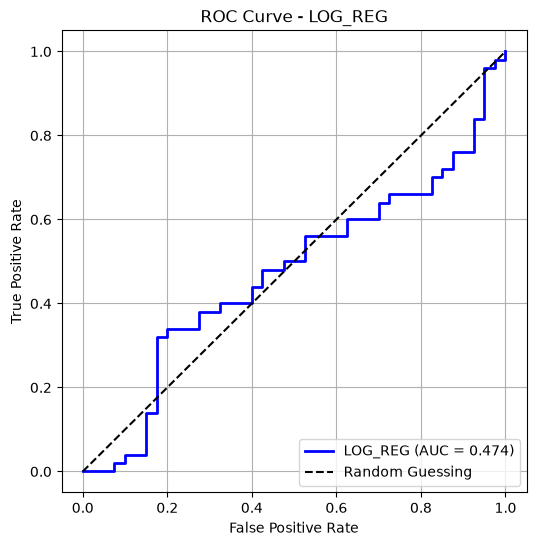

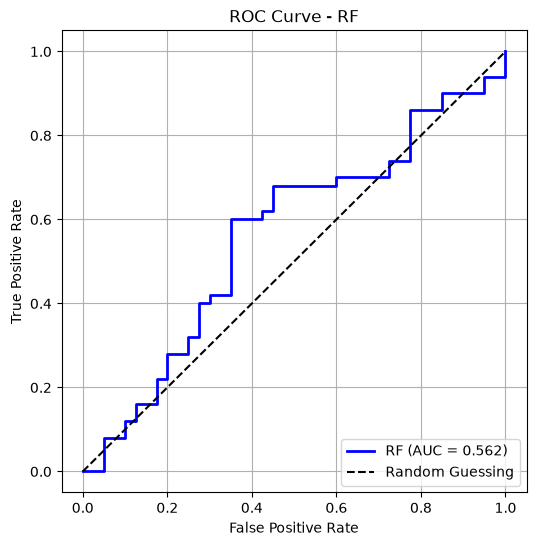

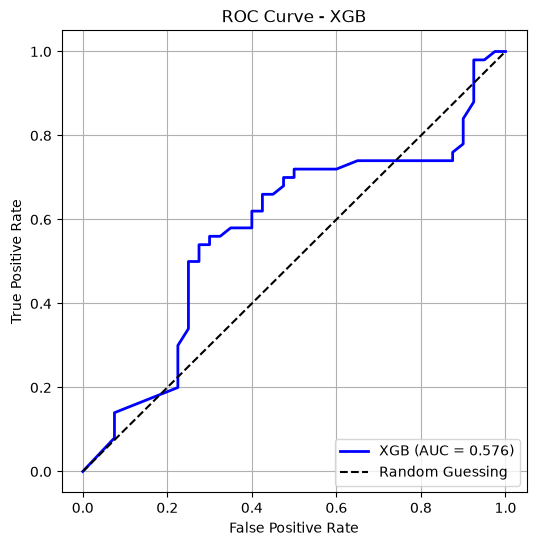

In [59]:
for name, data in performance_results.items():
    fpr, tpr, _ = roc_curve(y_test, data['y_proba'])
    
    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, label=f"{name.upper()} (AUC = {data['AUC-ROC']:.3f})", color='blue', linewidth=2)
    plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {name.upper()}')
    plt.legend(loc='lower right')
    plt.grid(True)
    plt.show()

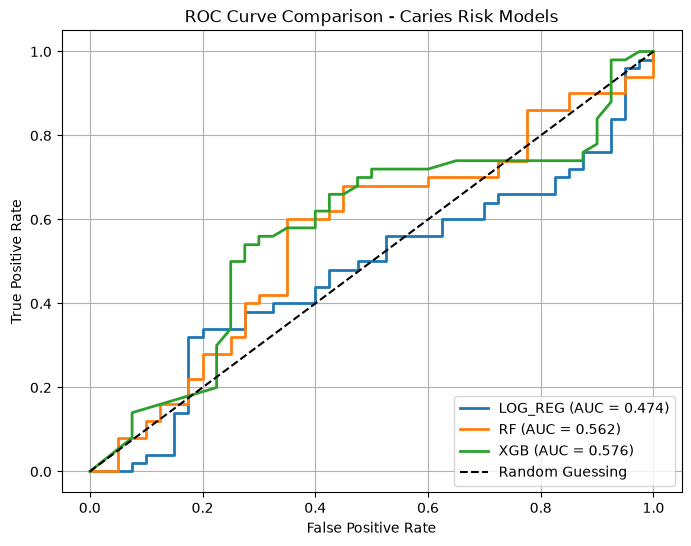

In [ ]:
# Combined ROC Plot and Export
plt.figure(figsize=(8, 6))

for name, data in performance_results.items():
    fpr, tpr, _ = roc_curve(y_test, data['y_proba'])
    
    plt.figure(figsize=(6, 6))
    plt.plot(fpr, tpr, label=f"{name.upper()} (AUC = {data['AUC-ROC']:.3f})", color='blue', linewidth=2)
    plt.plot([0, 1], [0, 1], 'k--', label='Random Guessing')
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'ROC Curve - {name.upper()}')
    plt.legend(loc='lower right')
    plt.grid(True)
    
    # Save individual ROC curve
    plt.savefig(FIGURES_DIR / f'roc_curve_{name}.png', dpi=300, bbox_inches='tight')
    plt.show()

ROC curve of each model in one graph:

## Export Best Model

Export the best performing caries risk prediction model for production

In [61]:
joblib.dump(grids[best_model_name].best_estimator_, MODELS_DIR / 'caries-risk-predictor.pkl')

['/home/rat/Projects/Caries Risk ML Prediction/caries-risk-prediction-ml/models/caries-risk-predictor.pkl']